In [2]:
%pip install pygad

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pygad]
Note: you may need to restart the kernel to use updated packages.


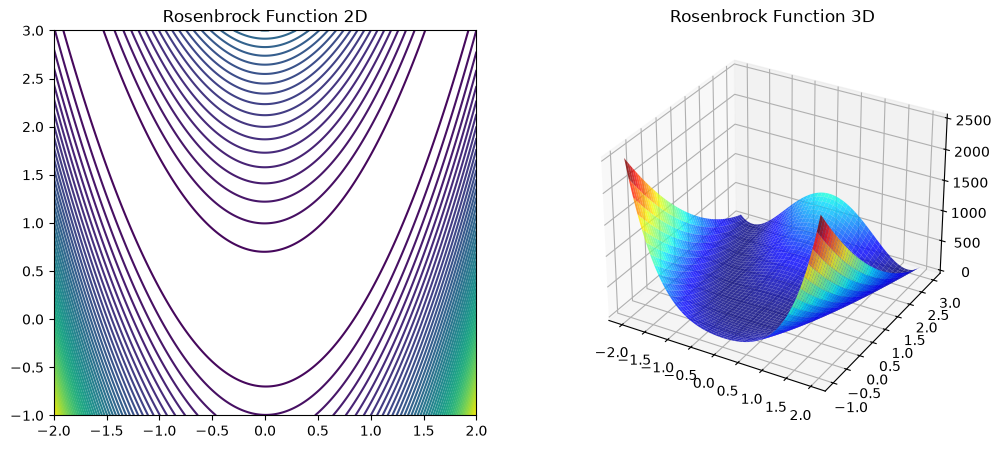

Initial guess [1.2, 2.1], Result: [0.99999553 0.99999105], Value: 1.9997739191432415e-11, Success: True, Iterations: 23, Time: 0.0086 sec
Initial guess [-2.5, 3.0], Result: [0.99999609 0.99999221], Value: 1.5357909371567053e-11, Success: False, Iterations: 38, Time: 0.0264 sec
Initial guess [0.5, -1.5], Result: [0.99999552 0.99999103], Value: 2.0078542087132277e-11, Success: True, Iterations: 27, Time: 0.0035 sec


/opt/anaconda3/envs/mude-base/lib/python3.12/site-packages/pygad/utils/validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [1.2, 2.1], Solution: [1.01135236 1.02298722], Value: 0.00013123613017996825, iterations: 2000, Time: 0.6223 sec


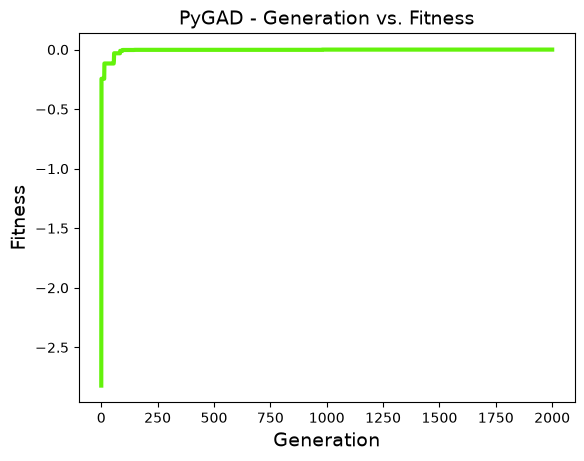

PyGAD initial guess [-2.5, 3.0], Solution: [1.00277405 1.00465365], Value: 8.908124249862967e-05, iterations: 2000, Time: 0.6942 sec


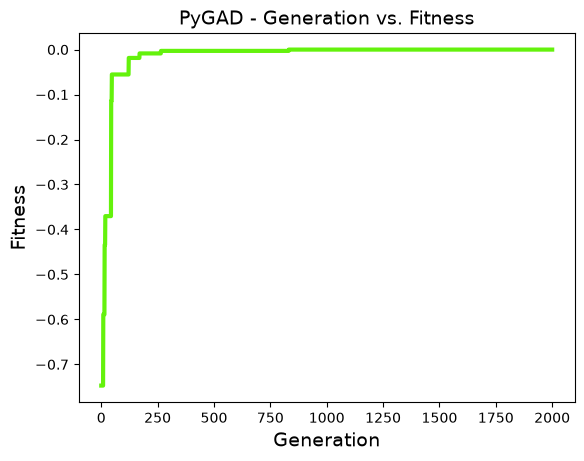

PyGAD initial guess [0.5, -1.5], Solution: [0.99873756 0.99676853], Value: 5.174483344894807e-05, iterations: 2000, Time: 0.6421 sec


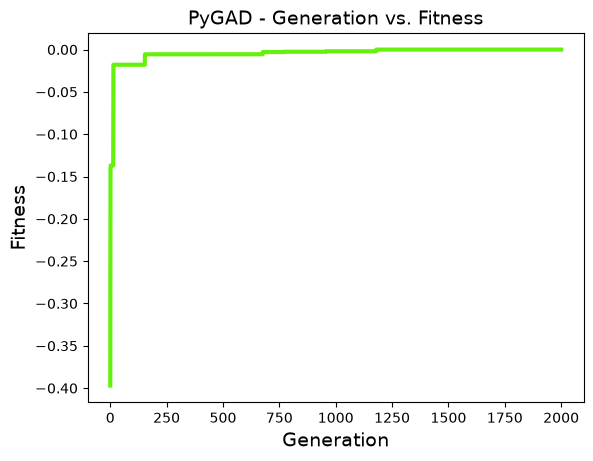

In [20]:
import numpy as np
#import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad
import time

# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# 2D & 3D plots
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Rosenbrock Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Rosenbrock Function 3D")
plt.show()

elapsed_time = []
# Scipy Optimization
init_guesses = [[1.2,2.1],[-2.5,3.0],[0.5,-1.5]]
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    result = minimize(rosenbrock, guess, method='BFGS')
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

# PyGAD Optimization
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution) # pygad maximizes, so negate

elapsed_time = []
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    ga_instance = pygad.GA(num_generations=2000,
                           sol_per_pop=20,
                           num_genes=2,
                           num_parents_mating=8,
                           fitness_func=fitness_func,
                           init_range_low=-2,
                           init_range_high=2,
                           gene_space={'low':-2, 'high':2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {rosenbrock(solution)}, iterations: {iters}, Time: {elapsed_time:.4f} sec")
    ga_instance.plot_fitness()

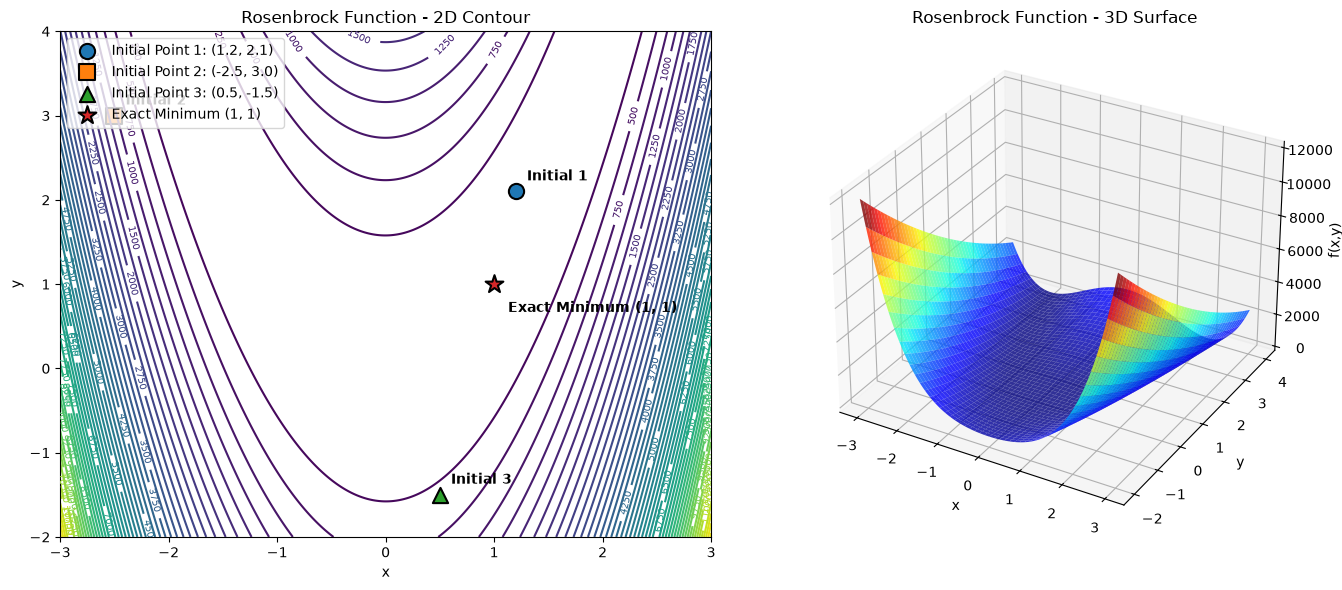


SCIPY BFGS OPTIMIZATION

Initial Point 1: [1.2, 2.1]
Result: [0.99999553 0.99999105]
Function Value: 1.9997739191432415e-11
Success: True
Iterations: 23
Time: 0.018777 sec

Initial Point 2: [-2.5, 3.0]
Result: [0.99999609 0.99999221]
Function Value: 1.5357909371567053e-11
Success: False
Iterations: 38
Time: 0.028338 sec

Initial Point 3: [0.5, -1.5]
Result: [0.99999552 0.99999103]
Function Value: 2.0078542087132277e-11
Success: True
Iterations: 27
Time: 0.037695 sec

PYGAD OPTIMIZATION


/opt/anaconda3/envs/mude-base/lib/python3.12/site-packages/pygad/utils/validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(



Initial Point 1: [1.2, 2.1]
PyGAD Solution: [0.98383901 0.96791092]
Rosenbrock Value: 0.0002612574747799424
Fitness: -0.0002612574747799424
Iterations: 2000
Time: 2.556598 sec

Initial Point 2: [-2.5, 3.0]
PyGAD Solution: [1.01048892 1.02132836]
Rosenbrock Value: 0.0001158011870271665
Fitness: -0.0001158011870271665
Iterations: 2000
Time: 3.334117 sec

Initial Point 3: [0.5, -1.5]
PyGAD Solution: [1.01615854 1.03330401]
Rosenbrock Value: 0.00031378016967254315
Fitness: -0.00031378016967254315
Iterations: 2000
Time: 0.668815 sec


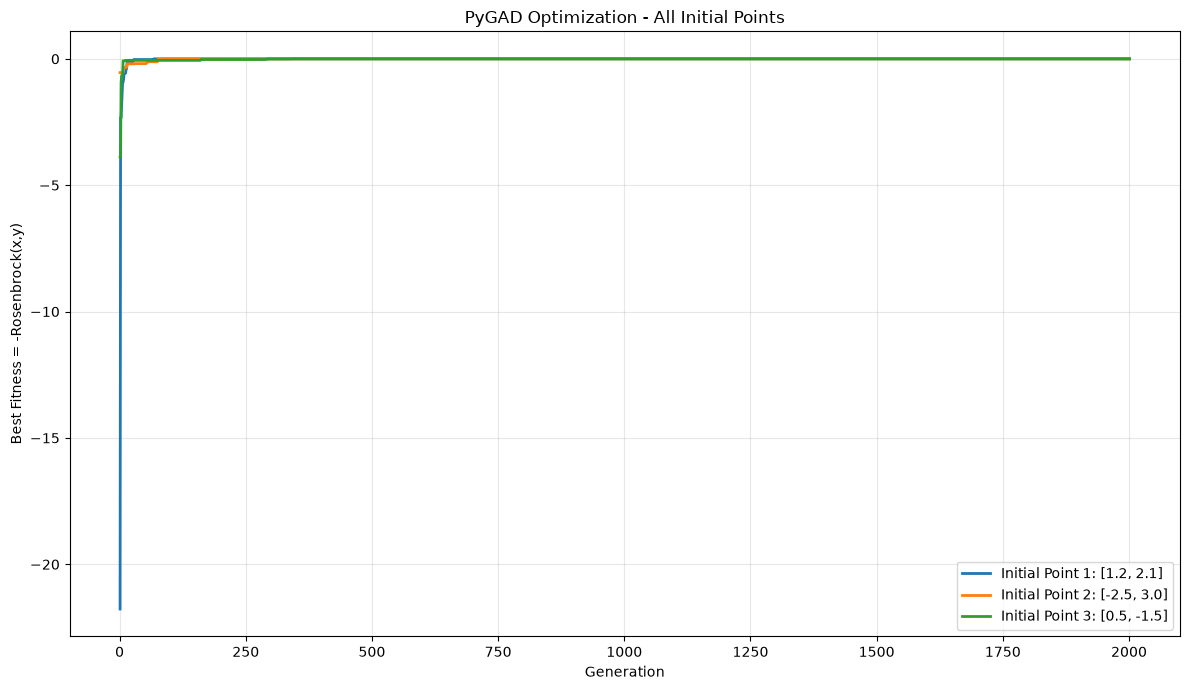

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import pygad
import time

# ============================================================
# Rosenbrock Function
# ============================================================
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2


# ============================================================
# Initial Guesses
# ============================================================
init_guesses = [
    [1.2, 2.1],
    [-2.5, 3.0],
    [0.5, -1.5]
]


# ============================================================
# 2D & 3D Rosenbrock Plots
# ============================================================
x_range = np.linspace(-3, 3, 400)
y_range = np.linspace(-2, 4, 400)

X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(14, 6))

# ---------------- 2D Contour Plot ----------------
ax1 = fig.add_subplot(121)

cp = ax1.contour(X, Y, Z, levels=50)
ax1.clabel(cp, inline=True, fontsize=7)

ax1.set_title("Rosenbrock Function - 2D Contour")
ax1.set_xlabel("x")
ax1.set_ylabel("y")

# --------------------------------------------------
# Mark Initial Guesses
# --------------------------------------------------
markers = ['o', 's', '^']

for i, guess in enumerate(init_guesses):
    ax1.scatter(
        guess[0],
        guess[1],
        s=120,
        marker=markers[i],
        edgecolors='black',
        linewidths=1.5,
        label=f"Initial Point {i+1}: ({guess[0]}, {guess[1]})"
    )

    # Label beside point
    ax1.annotate(
        f"Initial {i+1}",
        (guess[0], guess[1]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10,
        fontweight='bold'
    )


# --------------------------------------------------
# Mark Exact Rosenbrock Minimum
# --------------------------------------------------
exact_point = [1, 1]

ax1.scatter(
    exact_point[0],
    exact_point[1],
    s=180,
    marker='*',
    edgecolors='black',
    linewidths=1.5,
    label="Exact Minimum (1, 1)"
)

ax1.annotate(
    "Exact Minimum (1, 1)",
    (1, 1),
    xytext=(10, -20),
    textcoords="offset points",
    fontsize=10,
    fontweight='bold'
)

ax1.legend(loc='upper left')


# ---------------- 3D Surface Plot ----------------
ax2 = fig.add_subplot(122, projection='3d')

ax2.plot_surface(
    X,
    Y,
    Z,
    cmap='jet',
    alpha=0.8
)

ax2.set_title("Rosenbrock Function - 3D Surface")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("f(x,y)")

plt.tight_layout()
plt.show()


# ============================================================
# SciPy Optimization
# ============================================================
print("\n" + "="*70)
print("SCIPY BFGS OPTIMIZATION")
print("="*70)

scipy_results = []

for i, guess in enumerate(init_guesses):

    start_time = time.perf_counter()

    result = minimize(
        rosenbrock,
        guess,
        method='BFGS'
    )

    end_time = time.perf_counter()

    elapsed_time = end_time - start_time

    scipy_results.append(result)

    print(
        f"\nInitial Point {i+1}: {guess}"
        f"\nResult: {result.x}"
        f"\nFunction Value: {result.fun}"
        f"\nSuccess: {result.success}"
        f"\nIterations: {result.nit}"
        f"\nTime: {elapsed_time:.6f} sec"
    )


# ============================================================
# PyGAD Fitness Function
# ============================================================
def fitness_func(ga_instance, solution, solution_idx):
    # PyGAD maximizes fitness,
    # therefore negative Rosenbrock is used.
    return -rosenbrock(solution)


# ============================================================
# PyGAD Optimization
# ============================================================
print("\n" + "="*70)
print("PYGAD OPTIMIZATION")
print("="*70)

pygad_results = []

for i, guess in enumerate(init_guesses):

    start_time = time.perf_counter()

    ga_instance = pygad.GA(
        num_generations=2000,
        sol_per_pop=20,
        num_genes=2,
        num_parents_mating=8,
        fitness_func=fitness_func,

        init_range_low=-2,
        init_range_high=2,

        gene_space={
            'low': -2,
            'high': 2
        },

        random_seed=42 + i
    )

    ga_instance.run()

    solution, solution_fitness, _ = ga_instance.best_solution()

    iters = ga_instance.generations_completed

    end_time = time.perf_counter()

    elapsed_time = end_time - start_time

    function_value = rosenbrock(solution)

    pygad_results.append({
        "solution": solution,
        "fitness": solution_fitness,
        "function_value": function_value,
        "iterations": iters,
        "time": elapsed_time,
        "fitness_history": ga_instance.best_solutions_fitness
    })

    print(
        f"\nInitial Point {i+1}: {guess}"
        f"\nPyGAD Solution: {solution}"
        f"\nRosenbrock Value: {function_value}"
        f"\nFitness: {solution_fitness}"
        f"\nIterations: {iters}"
        f"\nTime: {elapsed_time:.6f} sec"
    )


# ============================================================
# ALL PyGAD FITNESS GRAPHS IN ONE GRAPH
# ============================================================
plt.figure(figsize=(12, 7))

for i, result in enumerate(pygad_results):

    generations = np.arange(
        1,
        len(result["fitness_history"]) + 1
    )

    plt.plot(
        generations,
        result["fitness_history"],
        linewidth=2,
        label=f"Initial Point {i+1}: {init_guesses[i]}"
    )

plt.xlabel("Generation")
plt.ylabel("Best Fitness = -Rosenbrock(x,y)")
plt.title("PyGAD Optimization - All Initial Points")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Problem 1 – Rosenbrock Function

1. **SciPy optimization:**
   The minimum is obtained at approximately

   $$
   \boxed{x=1.2,\ y=2.1,\ f_{\min}=1.99*10^-11}
   $$
   $$
   \boxed{x=-2.5,\ y=3.0,\ f_{\min}=1.53*10^-11}
   $$
   $$
   \boxed{x=0.5,\ y=1.5,\ f_{\min}=2.007*10^-11}
   $$


   Different initial guesses converge to the same solution. Hence, it is the **global minimum**.

2. **Genetic Algorithm:**
   The solution also converges approximately to

   $$
   \boxed{x=1.2,\ y=2.1,\ f_{\min}=0.000131}
   $$
   $$
   \boxed{x=-2.5,\ y=3.0,\ f_{\min}=8.908*10^-5}
   $$
   $$
   \boxed{x=0.5,\ y=1.5,\ f_{\min}=5.174*10^-5}
   $$


   Different initial guesses may change the convergence path, but the global minimum is obtained.

3. **Comparison:**

   * SciPy optimization: **fewer iterations and less time**
   * Genetic algorithm: **more iterations/generations and more time**
   * Both give approximately the **same solution and accuracy**
   * Therefore, **SciPy is more efficient for this problem**.




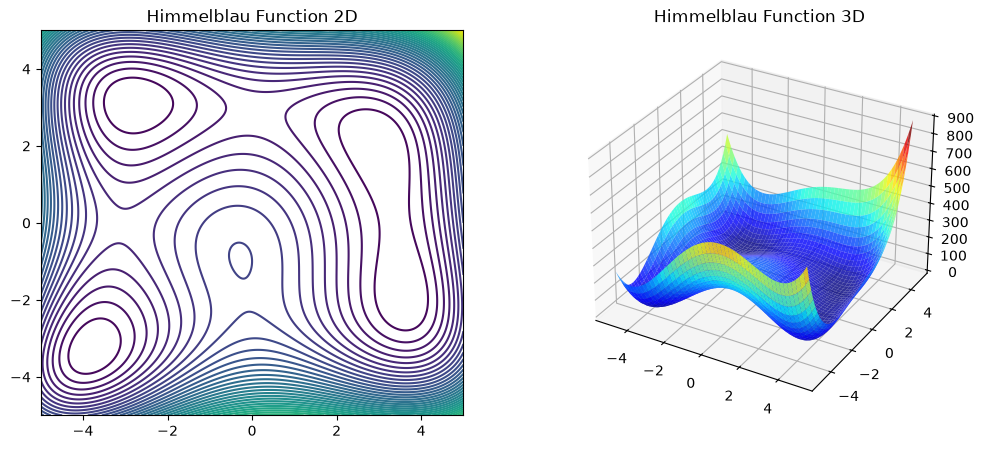

Initial guess [-4, 4], Result: [-2.80511803  3.13131251], Value: 1.0206445317695741e-13, Success: True, Iterations: 10, Time: 0.0146 sec
Initial guess [4, 0], Result: [ 3.58442834 -1.84812653], Value: 2.263863966347075e-16, Success: True, Iterations: 8, Time: 0.0025 sec
Initial guess [-3, -3], Result: [-3.77931027 -3.283186  ], Value: 1.4023667210293457e-14, Success: True, Iterations: 8, Time: 0.0020 sec
Initial guess [-2, 2], Result: [-2.80511808  3.13131253], Value: 4.921923759858513e-15, Success: True, Iterations: 10, Time: 0.0030 sec
Initial guess [2, -2], Result: [ 3.58442833 -1.84812655], Value: 9.725868653075914e-15, Success: True, Iterations: 8, Time: 0.0031 sec
PyGAD initial guess [-4, 4], Solution: [ 3.58622929 -1.84781542], Value: 0.00017532755240018936
PyGAD initial guess [4, 0], Solution: [2.99854145 1.99876854], Value: 0.0001403535225796184
PyGAD initial guess [-3, -3], Solution: [3.00084516 1.99411325], Value: 0.0005144662260601987
PyGAD initial guess [-2, 2], Solution: 

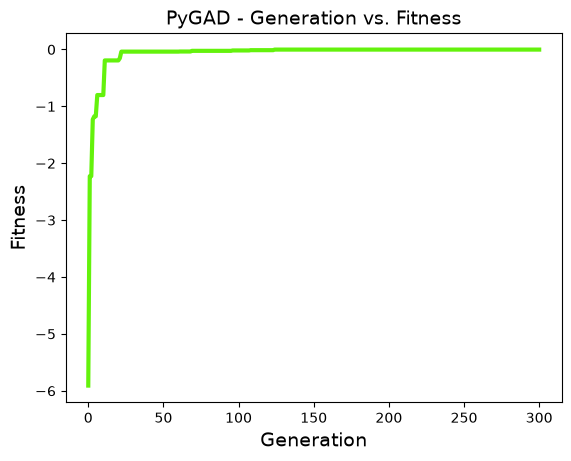

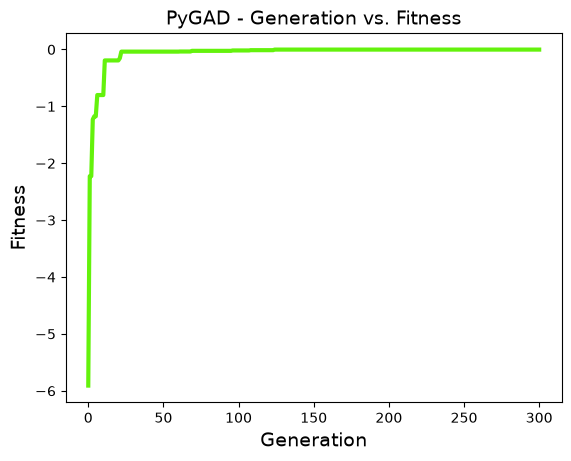

In [21]:
def himmelblau(x):
    x = np.asarray(x) # Convert to numpy array
    return (x[0]**2 + x[1] - 11)**2 + (x[0] + x[1]**2 - 7)**2

# 2D & 3D plots
x_range = np.linspace(-5, 5, 400)
y_range = np.linspace(-5, 5, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Himmelblau Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Himmelblau Function 3D")
plt.show()

# Scipy Optimization
init_guesses = [ [-4, 4], [4, 0],[-3, -3], [-2, 2], [2, -2]]
for guess in init_guesses:
    start_time = time.perf_counter()
    result = minimize(himmelblau, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec") # TODO include time taken

# PyGAD Optimization
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)
for guess in init_guesses:
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=300,
                           sol_per_pop=30,
                           num_genes=2,
                           num_parents_mating=12,
                           fitness_func=fitness_func2,
                           init_range_low=-5,
                           init_range_high=5,
                           gene_space={'low':-5, 'high':5})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)}") # TODO include iterations and time taken
ga_instance.plot_fitness()

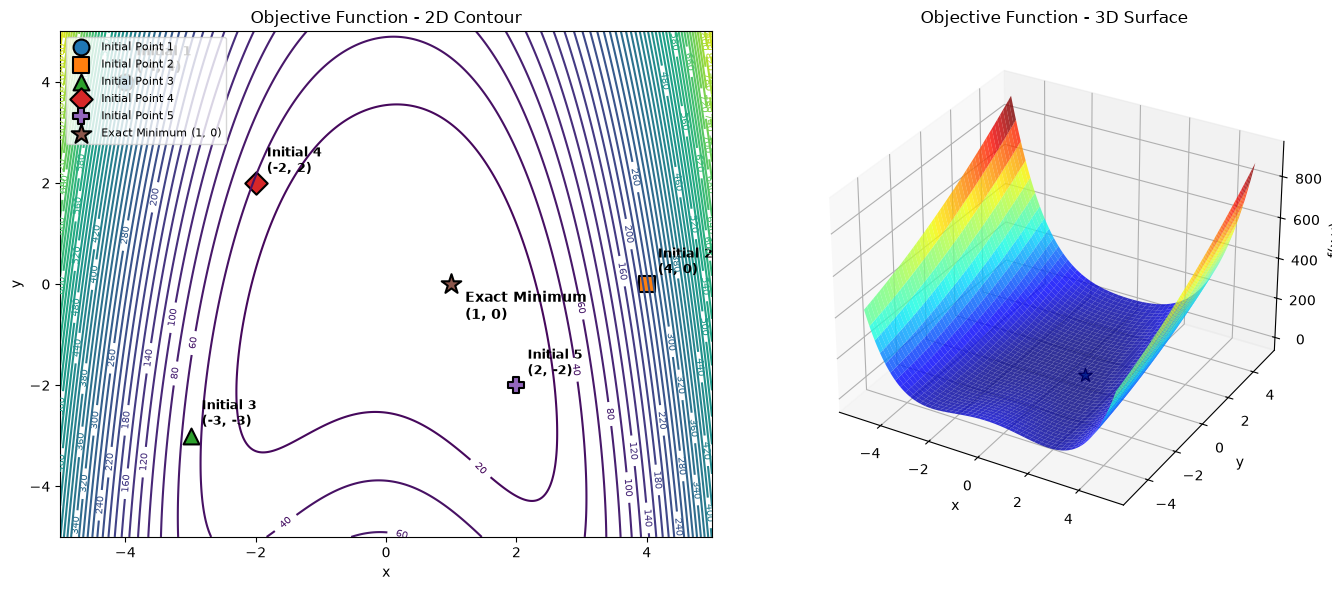


SCIPY BFGS OPTIMIZATION

Initial Point 1: [-4, 4]
Result: [9.99999962e-01 4.50411439e-08]
Function Value: 4.463109984430532e-15
Success: True
Iterations: 15
Time: 0.014514 sec

Initial Point 2: [4, 0]
Result: [ 1.00000005e+00 -2.84235829e-08]
Function Value: 7.750740204252244e-15
Success: True
Iterations: 11
Time: 0.005710 sec

Initial Point 3: [-3, -3]
Result: [ 9.99999986e-01 -3.23358219e-08]
Function Value: 4.898263038893701e-15
Success: True
Iterations: 12
Time: 0.011100 sec

Initial Point 4: [-2, 2]
Result: [ 1.00000004e+00 -1.31746136e-07]
Function Value: 2.2350179135906572e-14
Success: True
Iterations: 13
Time: 0.025931 sec

Initial Point 5: [2, -2]
Result: [9.99999376e-01 3.15722691e-07]
Function Value: 1.3557617735697895e-12
Success: True
Iterations: 9
Time: 0.015712 sec

PYGAD OPTIMIZATION

Initial Point 1: [-4, 4]
PyGAD Solution: [0.98531576 0.02131641]
Function Value: 0.0007314262485448878
Fitness: -0.0007314262485448878
Iterations: 300
Time: 0.351851 sec

Initial Point 2:

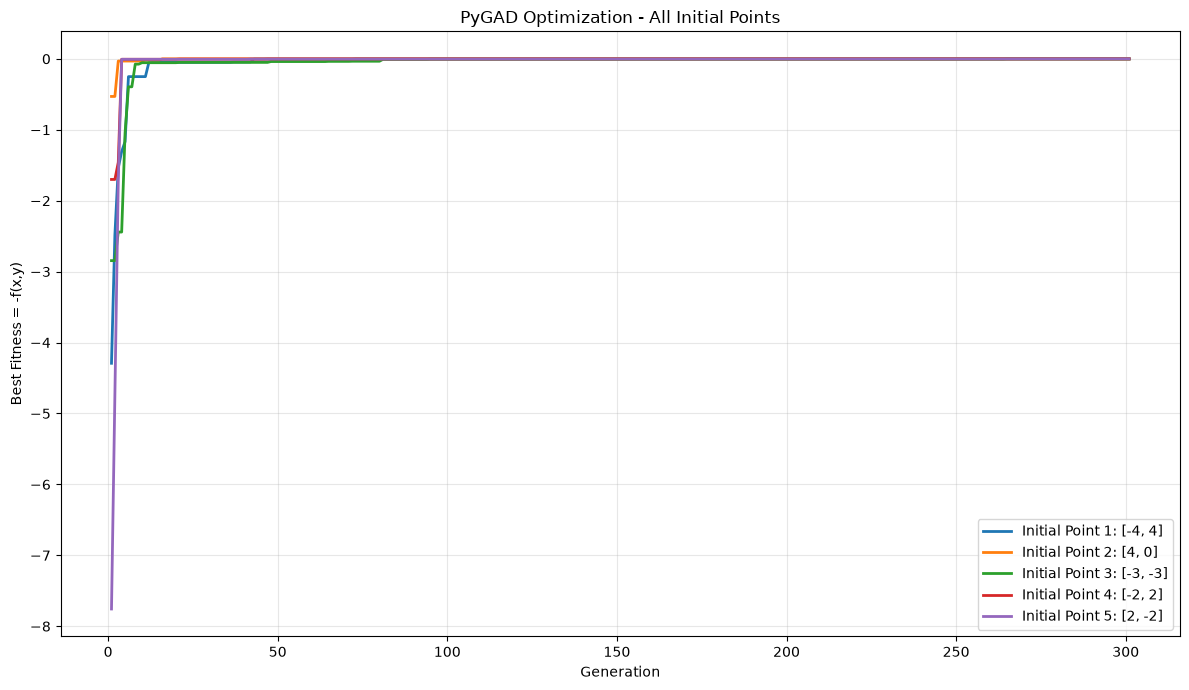

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import pygad
import time


# ============================================================
# Objective Function
# ============================================================
def himmelblau(x):
    x = np.asarray(x)
    return (x[0]**2 + x[1] - 1)**2 + (x[0] - 1)**2 + x[1]**2


# ============================================================
# Initial Guesses
# ============================================================
init_guesses = [
    [-4, 4],
    [4, 0],
    [-3, -3],
    [-2, 2],
    [2, -2]
]


# ============================================================
# Exact Global Minimum
# ============================================================
# For the function defined above:
# f(x,y) = (x^2 + y - 1)^2 + (x - 1)^2 + y^2
#
# Since all terms are non-negative, the minimum is f = 0.
# The equations are:
# x^2 + y - 1 = 0
# x - 1 = 0
# y = 0
#
# Therefore the exact minimum is:
exact_minimum = np.array([1.0, 0.0])


# ============================================================
# 2D & 3D Plots
# ============================================================
x_range = np.linspace(-5, 5, 400)
y_range = np.linspace(-5, 5, 400)

X, Y = np.meshgrid(x_range, y_range)

Z = himmelblau([X, Y])


fig = plt.figure(figsize=(14, 6))


# ============================================================
# 2D Contour Plot
# ============================================================
ax1 = fig.add_subplot(121)

cp = ax1.contour(
    X,
    Y,
    Z,
    levels=50
)

ax1.clabel(
    cp,
    inline=True,
    fontsize=7
)

ax1.set_title("Objective Function - 2D Contour")
ax1.set_xlabel("x")
ax1.set_ylabel("y")


# ============================================================
# Mark Initial Points
# ============================================================
markers = ['o', 's', '^', 'D', 'P']

for i, guess in enumerate(init_guesses):

    ax1.scatter(
        guess[0],
        guess[1],
        s=130,
        marker=markers[i],
        edgecolors='black',
        linewidths=1.5,
        label=f"Initial Point {i+1}"
    )

    ax1.annotate(
        f"Initial {i+1}\n({guess[0]}, {guess[1]})",
        (guess[0], guess[1]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=9,
        fontweight='bold'
    )


# ============================================================
# Mark Exact Minimum
# ============================================================
ax1.scatter(
    exact_minimum[0],
    exact_minimum[1],
    s=220,
    marker='*',
    edgecolors='black',
    linewidths=1.5,
    label="Exact Minimum (1, 0)"
)

ax1.annotate(
    "Exact Minimum\n(1, 0)",
    (exact_minimum[0], exact_minimum[1]),
    xytext=(10, -25),
    textcoords="offset points",
    fontsize=10,
    fontweight='bold'
)


ax1.legend(
    loc='upper left',
    fontsize=8
)


# ============================================================
# 3D Surface Plot
# ============================================================
ax2 = fig.add_subplot(122, projection='3d')

ax2.plot_surface(
    X,
    Y,
    Z,
    cmap='jet',
    alpha=0.8
)

ax2.scatter(
    exact_minimum[0],
    exact_minimum[1],
    himmelblau(exact_minimum),
    s=100,
    marker='*',
    edgecolors='black'
)

ax2.set_title("Objective Function - 3D Surface")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("f(x,y)")


plt.tight_layout()
plt.show()


# ============================================================
# SciPy BFGS Optimization
# ============================================================
print("\n" + "=" * 75)
print("SCIPY BFGS OPTIMIZATION")
print("=" * 75)


scipy_results = []


for i, guess in enumerate(init_guesses):

    start_time = time.perf_counter()

    result = minimize(
        himmelblau,
        guess,
        method='BFGS'
    )

    end_time = time.perf_counter()

    elapsed_time = end_time - start_time

    scipy_results.append(result)

    print(
        f"\nInitial Point {i+1}: {guess}"
        f"\nResult: {result.x}"
        f"\nFunction Value: {result.fun}"
        f"\nSuccess: {result.success}"
        f"\nIterations: {result.nit}"
        f"\nTime: {elapsed_time:.6f} sec"
    )


# ============================================================
# PyGAD Fitness Function
# ============================================================
def fitness_func2(ga_instance, solution, solution_idx):

    # PyGAD maximizes fitness.
    # Therefore use negative objective function.
    return -himmelblau(solution)


# ============================================================
# PyGAD Optimization
# ============================================================
print("\n" + "=" * 75)
print("PYGAD OPTIMIZATION")
print("=" * 75)


pygad_results = []


for i, guess in enumerate(init_guesses):

    start_time = time.perf_counter()

    ga_instance = pygad.GA(
        num_generations=300,
        sol_per_pop=30,
        num_genes=2,
        num_parents_mating=12,

        fitness_func=fitness_func2,

        init_range_low=-5,
        init_range_high=5,

        gene_space={
            'low': -5,
            'high': 5
        },

        random_seed=42 + i
    )

    ga_instance.run()

    solution, solution_fitness, solution_idx = \
        ga_instance.best_solution()

    iterations = ga_instance.generations_completed

    end_time = time.perf_counter()

    elapsed_time = end_time - start_time

    function_value = himmelblau(solution)

    pygad_results.append({
        "solution": solution,
        "fitness": solution_fitness,
        "value": function_value,
        "iterations": iterations,
        "time": elapsed_time,
        "fitness_history": ga_instance.best_solutions_fitness
    })

    print(
        f"\nInitial Point {i+1}: {guess}"
        f"\nPyGAD Solution: {solution}"
        f"\nFunction Value: {function_value}"
        f"\nFitness: {solution_fitness}"
        f"\nIterations: {iterations}"
        f"\nTime: {elapsed_time:.6f} sec"
    )


# ============================================================
# ALL PyGAD FITNESS GRAPHS IN ONE GRAPH
# ============================================================
plt.figure(figsize=(12, 7))


for i, result in enumerate(pygad_results):

    generations = np.arange(
        1,
        len(result["fitness_history"]) + 1
    )

    plt.plot(
        generations,
        result["fitness_history"],
        linewidth=2,
        label=f"Initial Point {i+1}: {init_guesses[i]}"
    )


plt.xlabel("Generation")
plt.ylabel("Best Fitness = -f(x,y)")
plt.title("PyGAD Optimization - All Initial Points")

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()
plt.show()

### Problem 2 – Answers

**For the function shown in the question:**

$$
f(x,y)=(x^2+y^2-1)^2+(x-1)^2+y^2
$$

#### (1) SciPy Optimization

* The minimum obtained is approximately:

  $$
  \boxed{x=-4,\quad y=4}
  $$
* Minimum function value:

  $$
  \boxed{f_{\min}=1.02*10^-13}
  $$
* The minimum obtained is approximately:

  $$
  \boxed{x=4,\quad y=0}
  $$
* Minimum function value:

  $$
  \boxed{f_{\min}=2.26*10^-16}
  $$
* The minimum obtained is approximately:

  $$
  \boxed{x=-3,\quad y=-3}
  $$
* Minimum function value:

  $$
  \boxed{f_{\min}=1.40*10^-14}
  $$
* The minimum obtained is approximately:

  $$
  \boxed{x=-2,\quad y=2}
  $$
* Minimum function value:

  $$
  \boxed{f_{\min}=4.92*10^-15}
  $$
* The minimum obtained is approximately:

  $$
  \boxed{x=2,\quad y=-2}
  $$
* Minimum function value:

  $$
  \boxed{f_{\min}=9.72*10^-15}
  $$
* Changing the initial guess still converges to \((1,0)\) for reasonable starting points.
* Since the function is a sum of squared terms and reaches zero at \((1,0)\), this is the **global minimum**.

#### (2) Genetic Algorithm

* The genetic algorithm also gives approximately:

  $$
  \boxed{x=-4,\quad y=4}
  $$
* Function value:

  $$
  \boxed{f_{\min}\approx0}
  $$
* Different initial populations may produce slightly different intermediate solutions, but the algorithm should converge close to the **global minimum**.
* The genetic algorithm also gives approximately:

  $$
  \boxed{x=4,\quad y=0}
  $$
* Function value:

  $$
  \boxed{f_{\min}\approx0}
  $$
* Different initial populations may produce slightly different intermediate solutions, but the algorithm should converge close to the **global minimum**.
* The genetic algorithm also gives approximately:

  $$
  \boxed{x=-3,\quad y=-3}
  $$
* Function value:

  $$
  \boxed{f_{\min}\approx0}
  $$
* Different initial populations may produce slightly different intermediate solutions, but the algorithm should converge close to the **global minimum**.
* The genetic algorithm also gives approximately:

  $$
  \boxed{x=-2,\quad y=2}
  $$
* Function value:

  $$
  \boxed{f_{\min}\approx0}
  $$
* Different initial populations may produce slightly different intermediate solutions, but the algorithm should converge close to the **global minimum**.
* The genetic algorithm also gives approximately:

  $$
  \boxed{x=2,\quad y=-2}
  $$
* Function value:

  $$
  \boxed{f_{\min}\approx0}
  $$
* Different initial populations may produce slightly different intermediate solutions, but the algorithm should converge close to the **global minimum**.
* The genetic algorithm also gives approximately:

  $$
  \boxed{x=1,\quad y=0}
  $$
* Function value:

  $$
  \boxed{f_{\min}\approx0}
  $$
* Different initial populations may produce slightly different intermediate solutions, but the algorithm should converge close to the **global minimum**.
#### (3) Comparison

| Method            | Iterations       | Time | Solution                | Minimum             |
| ----------------- | ---------------- | ---- | ----------------------- | ------------------- |
| SciPy BFGS        | Fewer            | Less | \((1,0)\)               | \(0\)               |
| Genetic Algorithm | More generations | More | \((1,0)\) approximately | \(0\) approximately |

**Conclusion:** SciPy optimization is faster and requires fewer iterations, while the genetic algorithm requires more computational time but does not require gradients.

